In [1]:
source('../../../R/preamble.R')

In [2]:
gc = read.tsv('../../../datasets/phage/C20-21_resistance/2025-05-28 C torture alpha test.tsv') %>% 
    mutate(
        t = ymd_hms(time),
        elapsed = (t - min(t)) / 3600,
        #strain = strains[substr(name, 1, 2)],
        strain = factor(substr(name, 1, 2), levels = c('WT', '20', '21', 'AV'), labels = c('WT (sensitive)', 'C (50,000)', 'C (52,500)', 'ΔfhuA (resistant)')),
        phage = substr(name, 3, 3),
        rep = substr(name, 4, 4)
    )

Don't know how to automatically pick scale for object of type <difftime>.
Defaulting to continuous.


Don't know how to automatically pick scale for object of type <difftime>.
Defaulting to continuous.


Don't know how to automatically pick scale for object of type <difftime>.
Defaulting to continuous.


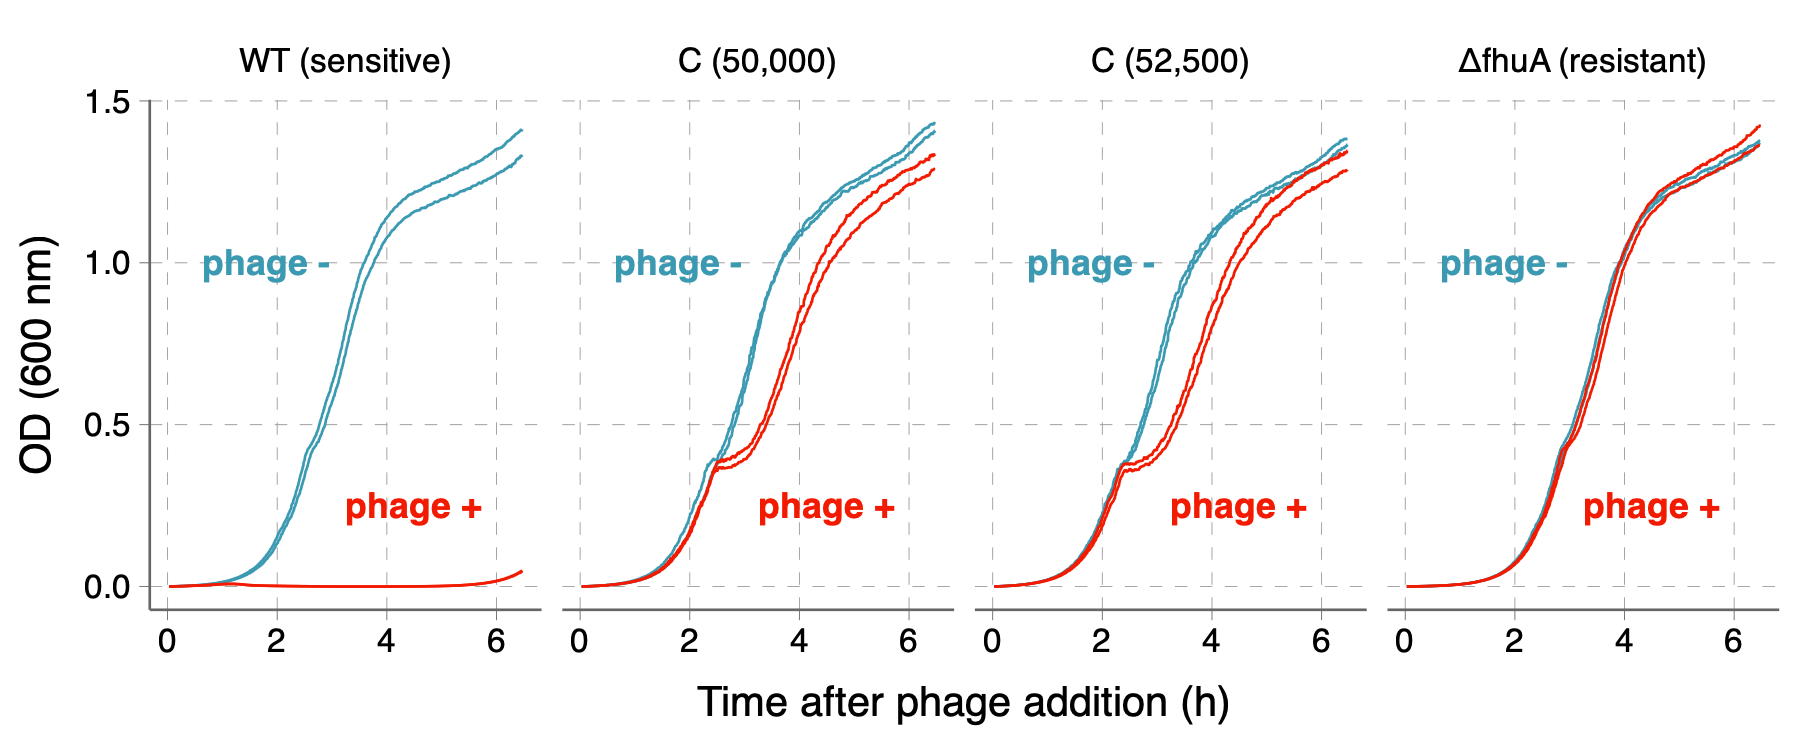

In [3]:
library(slider)
options(warn = -1)
size(2.5, 6)

lwd = 0.3
bw = 10

colors = c(pal[1], pal[5])

gc %>% 
    filter(elapsed < 6.5) %>% 
    arrange(elapsed) %>% 
    group_by(name) %>%
    mutate(
        s_od = slide_dbl(
            converted_od, 
            median, .before = bw, .after = bw, .complete = TRUE
        )
    ) %>% 

ggplot() + aes(elapsed, s_od, col = phage, group = name) + 
    
    facet_grid(~strain) + theme(legend.position = 'none') +

    geom_line(lwd=lwd) +

    annotate(geom = 'text', label = 'phage -', col = colors[1], x = 1.8, y = 1, size = 3, fontface = 'bold') +
    annotate(geom = 'text', label = 'phage +', col = colors[2], x = 4.5, y = 0.25, size = 3, fontface = 'bold') +

    labs(x = 'Time after phage addition (h)', y = 'OD (600 nm)')

psave('Plots/C20-21_still_has_sensitive_cells')